## **Lab 3: Spectral Representation**

The goal of this lab is to connect the time-domain signal you have been working with to its frequency-domain representation. The theory summary on spectrum representation introduces two complementary views of the same signal:

- the Fourier transform, which gives the frequency content of a signal segment, and
- the spectrogram, which shows how that content changes over time.

In this lab we will first compute the magnitude spectrum of a short fragment of the reference audio, then we will compute a spectrogram of the whole sound. The goal is not only to produce plots, but also to interpret them and relate them back to the sound you hear.

A periodic signal contains energy at its fundamental frequency and at its harmonics. When the signal is not perfectly periodic, the spectrum becomes less sharp and the energy spreads around those frequencies. In a short fragment, the FFT gives a snapshot of the dominant components. In a longer signal, the spectrogram shows how these components evolve over time.

In [1]:
import numpy as np
import librosa
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import Audio, display

from util import load_audio, plot_signals, plot_spectrogram, plot_spectrum

We will use the same reference sound from the previous labs. If you have your own audio file in a cloned repository, you can point the path there; otherwise the notebook will use the bundled reference file.

### 1. Spectrum Analysis

This section show how to compute the spectrum and the spectrogram of a sound

In [2]:
# Clone your own repository and point reference_path to your own audio file.
# \!git clone https://github.com/your-username/sis1_name.git
# reference_path = Path('./sis1_name/your_file.wav')

reference_path = Path('audio/reference.wav')
reference_audio, fs = load_audio(reference_path)
print(f'Using audio file: {reference_path}')

display(Audio(reference_audio, rate=fs))

Using audio file: audio/reference.wav


#### 1.1 Fourier transform of a short fragment

The first step is to look at a short fragment of the sound and compute its magnitude spectrum using the FFT. This gives a snapshot of the strongest frequency components present in that fragment.

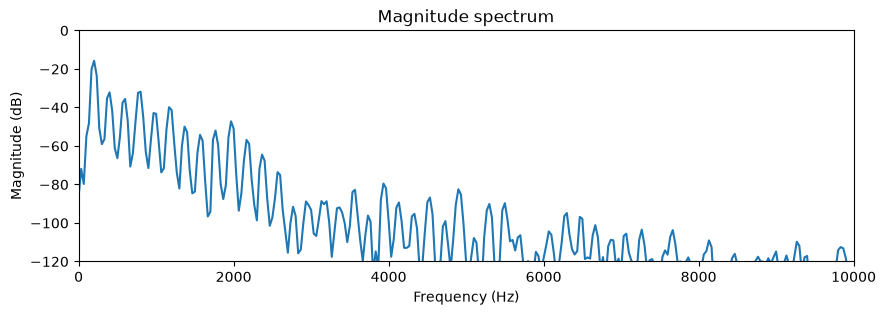

In [3]:
start = int(0.25 * fs)
end = int(0.28 * fs)
fragment = reference_audio[start:end]

ax = plot_spectrum(fragment, sr=fs)
ax.set_ylim([-120, 0])
ax.set_xlim([0, 10000])

plt.show()

#### 1.2 Questions

1. What are the strongest peaks in the magnitude spectrum? To what harmonics do they correspond?
   - Write your answer here.
   
2. Do you see a fundamental frequency and its harmonics? How did you identify them?
   - Write your answer here.

3. How would the spectrum change if the fragment were taken from a different part of the signal?
   - Write your answer here.

1. Los mayores picos se muestran en las frecuencias más bajas, ' algunos de estos picos podrían estar ' correspondiendo a los primeros armónicos. 

2. Veo una frecuencia fundamental, justo al lado del cero, con un pico relativamente bajo. El resto de frecuencias son sus harmónicos. Lo he identificado sabiendo que el MCD de los picos, es decir, de las frecuencias presentes en el espectrograma, sería la f0. La frecuencia presente justo al lado del cero, es la fundamental.

// corrección:
    se observa un pico cercanoa cero que podria ser la f0. Para identificarla realmente, deberíamos calcular el MCD de los picos, es decir, si las frecuencas mostradas en el espectro son múltiples de una fundamental común, aunque esta puede no aparecer en el espectro. 
    
3. El espectro cambiaría, y mostraría diferentes armónicos, ya que el audio, y su timbre, habría cambiado. 

// corrección:
    el espectro podría cambiar. si tiene un timbre diferente, tendrá distintos armónicos, con una distribución distinta. 

#### 1.3 Spectrogram of the whole sound

The FFT of one fragment gives a local snapshot, but a sound changes over time. A spectrogram shows how the frequency content evolves across the whole signal.

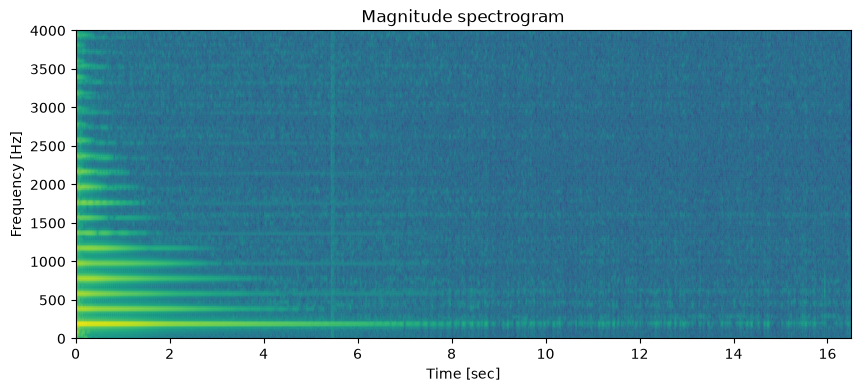

In [4]:
n_fft = 2048
hop_length = 256

ax = plot_spectrogram(reference_audio, sr=fs, N=n_fft, H=hop_length)
ax.set_ylim([0, 4000])
plt.show()

#### 1.4 Questions

1. Which frequencies are present for most of the sound? What does it mean from a perceptual point of view?
   - Write your answer here.

2. Do the bright bands stay fixed or do they change over time? What does it mean?
   - Write your answer here.

3. How does the spectrogram help explain why the sound changes over time? Describe the sound evolution.
   - Write your answer here.

1. For most of the sound, lower frequencies are present. From a perceptual point of view, this means it's a low-pitch sound. 

2. They change over time. That means some frequencies are only present at certain parts of the sound, as a result of the 'attack' of the string. 

3. The spectrogram helps explaining how the sound changes because it is a representation on which frequencies are present over time. The sound has more frequencies at the beginning, as a result of the attack of playing the string. Later, higher frequencies disappear first, to leave only lower frequencies, that will be disappearing over time. This corresponds to the decay of the sound after the string is plucked. 


#### 1.4 Fragment comparison

Repeat the spectral analysis for a different fragment of the signal and compare the magnitude spectra. Explain the difference.

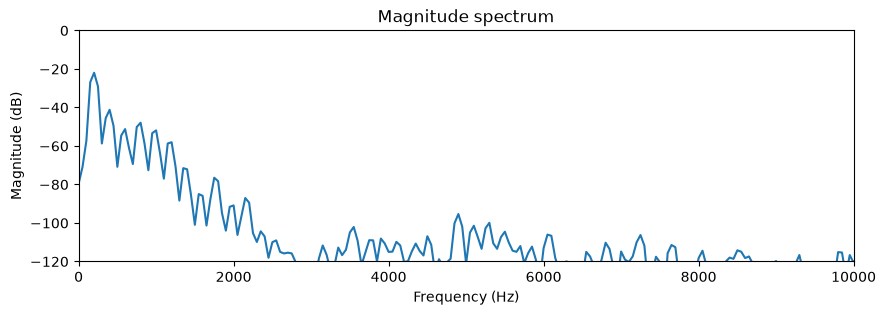

In [15]:
# Write the code here
start = int(1*fs)
end = int(1.02*fs)

fragment = reference_audio[start:end]

ax = plot_spectrum(fragment, sr=fs)
ax.set_ylim([-120, 0])
ax.set_xlim([0, 10000])

plt.show()


hay menos frecuencias presentes que en el grafico del inicio, ya que he mostrado el espectro de un intervalo más avanzado, y este tiene menos frecuencias debido al decay del sonido. 

corrección:
en este fragmento, hay muchas frecuencias con menor magnitud que en el inicial, especialmente a altas frecuencias. esto es debido al decay del sonido a través del tiempo. 

Choose a time where several harmonics are visible in the spectrogram and plot the spectrum at that time. Can you explain the result?

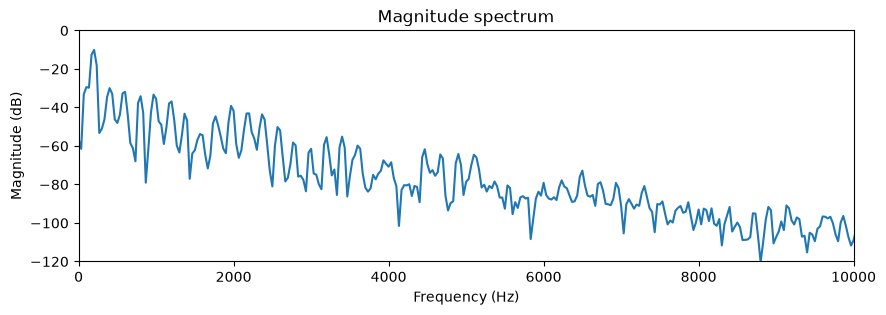

In [16]:
# Write the code here
start = int(0*fs)
end = int(0.03*fs)

fragment = reference_audio[start:end]

ax = plot_spectrum(fragment, sr=fs)
ax.set_ylim([-120, 0])
ax.set_xlim([0, 10000])

plt.show()

He mostrado el espectro en el momento incial. En este instante, hay muchas frecuencias con bastante magnitud, en comparación con otros intervalos del audio. Esto es debido a que el decaimiento del sonido es inferior ya que se acaba de pluck the string. 

correccion:
    i have plotted the spectrum of the initial fragment. at this moment, many freq components have relatively high magnitudes because the string has just been plucked. As the sound decays, the magnitude will decrease. 

Use the plots to estimate the weights of the fundamental frequency and a few harmonics. Store them in a list for later use. Be careful because the amplitude of the plot are in dB and you will need them in a linear scale, from 0 to 1, where 1 should be the maximum value of the spectrum. So you need to perform the conversion from dB to linear.

In [26]:
#weights = []  # Fill this list with the measured weights

weights_db=[-10, -30, -30, -30, -31, -40, -57, -45, -40]

max_db = max(weights_db)

weights_linear=[]
for i in range(len(weights_db)):
    weights_linear.append(10**((weights_db[i]-max_db)/20))

print(weights_linear)

[1.0, 0.1, 0.1, 0.1, 0.08912509381337455, 0.03162277660168379, 0.0044668359215096305, 0.01778279410038923, 0.03162277660168379]


### 2. Synthesis

Now we will use the harmonic synthesis idea from previous labs to build a signal from the estimated spectral weights.

In [27]:
def synthesize(f0, phi, Ak, t):
    y = np.zeros_like(t, dtype=float)
    for k in range(1, len(Ak) + 1):
        y += Ak[k - 1] * np.cos(2 * np.pi * k * f0 * t + k * phi - (k - 1) * np.pi / 2)
    return y

#### 2.1 Write the code

Use the `synthesize` function to generate a signal with the weights from part 1.3 and the fundamental frequency and phase from earlier labs. Plot the synthesized signal together with the reference so you can compare them directly.

In [44]:
# Write the synthesis code here
t=np.arange(0,16,1/fs)
y=synthesize(347.3482, 1, weights_linear, t)

(0.0, 5000.0)

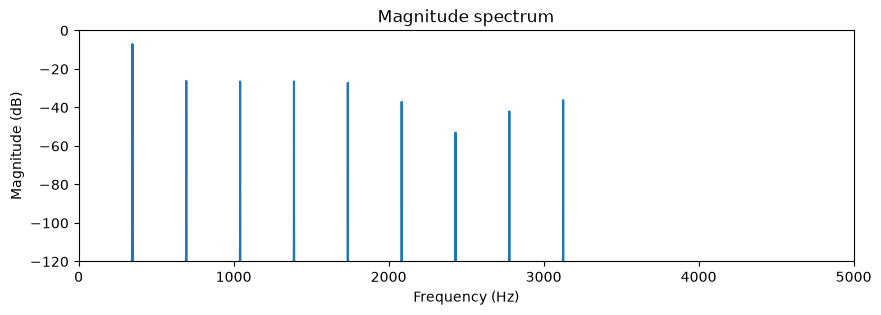

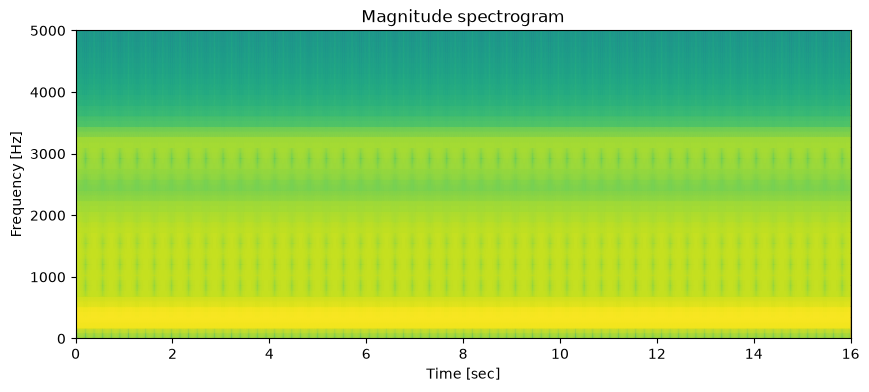

In [34]:
# Write the plotting code here, both time domain and spectrogram

ax=plot_spectrum(y, sr=fs)
ax.set_xlim(0,5000)
ax.set_ylim(-120,0)

ax2=plot_spectrogram(y, sr=fs)
ax2.set_xlim(0,16)
ax2.set_ylim(0,5000)

In [45]:

plot_signals([reference_audio,y], sr=fs, t_start=0.0, t_end = 0.03, name=["original", "syth"])


The synthesized signal does not match the original signal exactly. The synthesized waveform is more regular and has an almost constant amplitude, while the original signal has a different waveform and amplitude evolution. This may be due to errors in the estimated harmonic weights and phase, as well as the fact that the synthesis does not include the natural decay of the string.

In [46]:
Audio(y,rate=fs)



#### 2.2 Questions

1. What do you notice when you compare the synthesized spectrogram with the reference spectrogram?
   - Write your answer here.

2. Which parts of the sound are reproduced well, and which parts are still missing or different?
   - Write your answer here.

1. el espectrograma sintetizado es constante, ya que no se ha considerado el decaimiento de la nota en la reconstrucción. todas las amplitudes de las frecuencias son constantes.

2. la parte entre justo después del ataque y antes de que empieze a notarse de manera importante el decaimiento tiene un parecido razonable con el sonido sintetizado, pero sigue habiendo mucha diferencia de timbre debido a la imprecisión de la estimación de amplitudes o fases de la onda sintetizada 

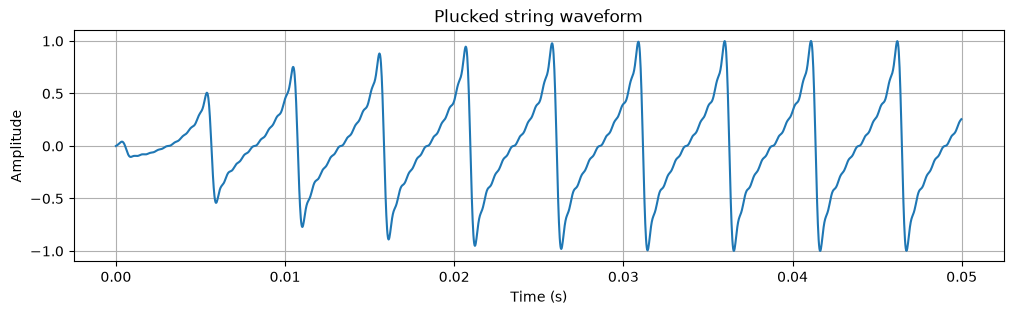

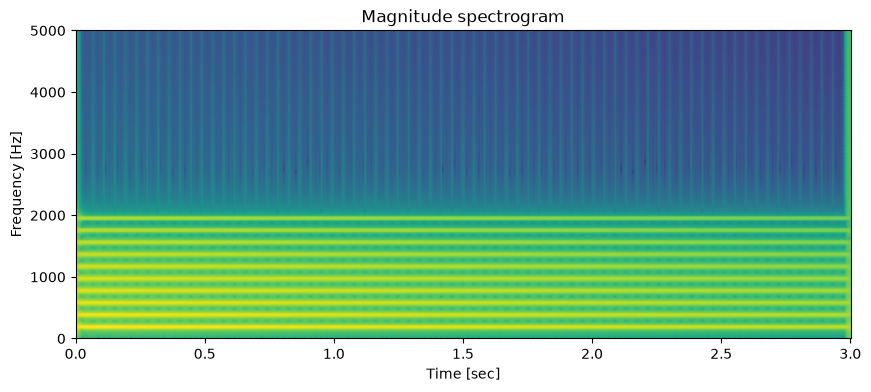

In [47]:

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display

# Parámetros
fs = 44100
duration = 3.0
f0 = 196.0  # Nota G3 (Sol)
phi = 0.9

# Vector de tiempos
t = np.arange(0, duration, 1/fs)

# Amplitudes de los primeros armónicos
weights = [1.0, 0.65, 0.45, 0.35, 0.25,
           0.18, 0.13, 0.10, 0.07, 0.05]

# Síntesis armónica
y = synthesize(f0, phi, weights, t)

# Envolvente: ataque rápido y decaimiento gradual
attack = 1 - np.exp(-t / 0.008)
decay = np.exp(-t / 1.2)
envelope = attack * decay

# Aplicar la envolvente
y = y * envelope

# Evitar saturación
y = y / np.max(np.abs(y))

# Escuchar
display(Audio(y, rate=fs))

# Representar la forma de onda
plt.figure(figsize=(12, 3))
plt.plot(t[:int(0.05*fs)], y[:int(0.05*fs)])
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Plucked string waveform")
plt.grid()
plt.show()

# Representar el espectrograma
ax = plot_spectrogram(y, sr=fs, N=2048, H=256)
ax.set_ylim(0, 5000)
plt.show()
